In [1]:
import os, warnings
from pathlib import Path
while not Path("pyproject.toml").exists() and Path.cwd() != Path.cwd().parent:
    os.chdir(Path.cwd().parent)  # run from the project root so data/ paths resolve (the notebook sits in studies/<name>/notebooks)
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display
from cifresignificative.studies.italy_productivity.analysis.data import *
from cifresignificative.core.viz.style import *
apply_style()
panel = load_panel()


# The MEF income tax returns by region, sector, age, turnover and income twentile
Notebook 32 used the returns by income class. The portal also publishes them by **region**, **sector of activity**, **age class**, **VAT-turnover class** and **twentile of reddito complessivo** (`ventili`); they were downloaded with `scripts/fetch_mef_irpef.py` (individuals only, tax years 2008-2024 where available) and parsed by `cifresignificative.core.sources.mef_irpef` into `data/processed/mef_irpef_dims.parquet`; analysis code `src/cifresignificative/studies/italy_productivity/analysis/irpef_dims.py`.
Same reading rules as notebook 32: tax year = filing year - 1; taxpayers are ranked or grouped by **reddito complessivo**, which excludes income taxed under the flat-rate regimes (`MIN` below = flat-rate filers: minimi, regime di vantaggio, regimi agevolati); amounts are euro (source: thousand euro). Two traps found while loading: NACE section names contain `;` (they broke the row split, fixed and verified), and tax year 2024 uses the **ATECO 2025** section list (some sections split or renamed; mapped back where one to one).
**Descriptive only.** These are declared incomes of taxpayers who file, not household income and not true income.

In [2]:
from cifresignificative.studies.italy_productivity.analysis import irpef_dims as ID
from cifresignificative.studies.italy_productivity.analysis import irpef as IR
from cifresignificative.core.sources import mef_irpef as MI
dm = pd.read_parquet(PROCESSED / "mef_irpef_dims.parquet").query("model != 'AE'"); inc = pd.read_parquet(PROCESSED / "mef_irpef.parquet")
print("rows:", len(dm), "| tables per classification:", dm.groupby("dimension").code.nunique().to_dict(), "| tax years:", dm.tax_year.min(), "-", dm.tax_year.max())
q = MI.qa(dm); ok = q[(q.suppressed == 0) & q.total.notna()]
print("class rows vs TOTALE row, cells without suppression:", len(ok), "| cells off by more than 0.5%:", int(((ok.class_sum_ratio - 1).abs() > 0.005).sum()), "| suppressed cells:", round(float(dm.suppressed.mean()) * 100, 2), "%")
p = dm[dm.measure.isin(["freq", "amount_keur", "mean_keur"]) & ~dm.is_total].pivot_table(index=["dimension", "code", "tax_year", "class_label", "variable"], columns="measure", values="value", observed=True)
p = p[(p.freq >= 1000) & p.amount_keur.notna() & p.mean_keur.notna()]; print("reported mean = amount / taxpayers (to rounding) in", round(float(((p.mean_keur - p.amount_keur / p.freq).abs() <= 0.0051).mean()) * 100, 2), "% of", len(p), "cells")
allv = pd.concat([inc, dm]); t = allv[(allv.variable == "taxpayers") & (allv.measure == "freq") & allv.is_total].groupby(["group", "tax_year", "dimension"]).value.max().unstack("dimension")
print("TOTALE taxpayers identical across income-class, region, sector, age and turnover tables (max relative difference):", float(t.sub(t.median(axis=1), axis=0).abs().div(t.median(axis=1), axis=0).max().max()))
print("empty files on the server: regional tables of 2016 for employees and pensioners (2 of 221)")
print("regions: all 20 present, Trentino and Alto Adige summed; regional rows add up to the TOTALE row in every year:", bool(((ID.by_class(dm, "region", "AAPFTOT0201").sum() / ID.by_class(dm, "region", "AAPFTOT0201", total=True).iloc[0]).round(4) == 1).all()))

rows: 823569 | tables per classification: {'activity': 9, 'age': 7, 'region': 17, 'turnover': 9, 'ventile': 1} | tax years: 2008 - 2024


class rows vs TOTALE row, cells without suppression: 14308 | cells off by more than 0.5%: 1 | suppressed cells: 3.67 %


reported mean = amount / taxpayers (to rounding) in 99.9 % of 164670 cells
TOTALE taxpayers identical across income-class, region, sector, age and turnover tables (max relative difference): 0.0
empty files on the server: regional tables of 2016 for employees and pensioners (2 of 221)
regions: all 20 present, Trentino and Alto Adige summed; regional rows add up to the TOTALE row in every year: True


## 1. Regions: declared income and the take-up of the flat-rate regimes

In [3]:
am = ID.area_mean(dm, "AAPFTOT0201"); rm = ID.regional_mean(dm, "AAPFTOT0201")
print("mean reddito complessivo per taxpayer, EUR, by macro-area (all individuals who file):"); display(am.round(0)[[2012, 2016, 2019, 2022, 2024]])
print("South / North-West:", (am.loc["South"] / am.loc["North-West"]).round(3)[[2012, 2016, 2019, 2024]].to_dict(), "| Islands / North-West:", (am.loc["Islands"] / am.loc["North-West"]).round(3)[[2012, 2024]].to_dict())
print("regions in 2024, highest and lowest:", rm[2024].round(0).sort_values().iloc[[0, 1, 2, -3, -2, -1]].to_dict())
dip, tit = ID.area_mean(dm, "AAPFDIP0201"), ID.area_mean(dm, "ABPFTIT0201"); print("VAT-number holders / employees, mean reddito complessivo, by macro-area (flat-regime income not included):"); display((tit / dip).round(2)[[2013, 2016, 2019, 2024]])
fs = ID.flat_share(dm, "region", "ABPFTIT0101", "ABPFMIN0101"); fs = fs.reindex([r for r in ID.AREA if r in fs.index])
print("flat-rate filers as a share of VAT-number holders, by region:"); display(fs[[2013, 2016, 2019, 2024]].round(3).sort_values(2024).T)
area = pd.Series(ID.AREA); fa = (ID.by_class(dm, "region", "ABPFMIN0101").reindex(area.index).groupby(area).sum() / ID.by_class(dm, "region", "ABPFTIT0101").reindex(area.index).groupby(area).sum()); print("by macro-area:"); display(fa[[2013, 2016, 2019, 2024]].round(3))

mean reddito complessivo per taxpayer, EUR, by macro-area (all individuals who file):


tax_year,2012,2016,2019,2022,2024
Centre,20208.0,21427.0,22041.0,23805.0,25910.0
Islands,15591.0,16402.0,16921.0,18447.0,20333.0
North-East,20492.0,22159.0,22968.0,24863.0,26941.0
North-West,22031.0,23519.0,24262.0,26170.0,28320.0
South,15328.0,16260.0,16748.0,18371.0,20239.0


South / North-West: {2012: 0.696, 2016: 0.691, 2019: 0.69, 2024: 0.715} | Islands / North-West: {2012: 0.708, 2024: 0.718}
regions in 2024, highest and lowest: {'Calabria': 18474.0, 'Molise': 19889.0, 'Puglia': 19936.0, 'Emilia Romagna': 27434.0, 'Trentino Alto Adige': 27978.0, 'Lombardia': 29421.0}


VAT-number holders / employees, mean reddito complessivo, by macro-area (flat-regime income not included):


tax_year,2013,2016,2019,2024
Centre,1.07,1.07,1.00,1.03
Islands,0.98,0.99,0.93,1.01
North-East,1.19,1.21,1.18,1.17
North-West,1.16,1.16,1.07,1.07
South,0.97,0.98,0.93,1.01


flat-rate filers as a share of VAT-number holders, by region:


class_label,Trentino Alto Adige,Basilicata,Molise,Puglia,Veneto,Calabria,Sardegna,Valle d'Aosta,Marche,Abruzzo,Emilia Romagna,Umbria,Sicilia,Friuli Venezia Giulia,Toscana,Piemonte,Lombardia,Liguria,Campania,Lazio
tax_year,,,,,,,,,,,,,,,,,,,,
2013,NaN,0.092,0.095,0.108,0.108,0.097,0.098,0.111,0.124,0.119,0.114,0.136,0.112,0.119,0.131,0.126,0.135,0.134,0.125,0.167
2016,0.168,0.203,0.206,0.233,0.208,0.231,0.210,0.237,0.243,0.241,0.221,0.257,0.253,0.239,0.256,0.251,0.247,0.288,0.272,0.306
2019,0.333,0.399,0.421,0.432,0.403,0.438,0.436,0.457,0.443,0.459,0.441,0.465,0.470,0.453,0.469,0.475,0.482,0.525,0.527,0.562
2024,0.379,0.425,0.447,0.462,0.473,0.479,0.492,0.492,0.494,0.500,0.502,0.505,0.511,0.514,0.518,0.530,0.547,0.557,0.561,0.603


by macro-area:


tax_year,2013,2016,2019,2024
Centre,0.147,0.277,0.509,0.554
Islands,0.108,0.242,0.461,0.506
North-East,0.112,0.211,0.415,0.478
North-West,0.132,0.253,0.485,0.543
South,0.113,0.245,0.470,0.504


## 2. Sectors of activity

In [4]:
s = ID.by_sector(dm, "ABPFTIT0105"); m = ID.by_sector(dm, "ABPFMIN0102"); fsec = (m / s)
last = 2023  # tax year 2024 follows the ATECO 2025 list
tab = pd.DataFrame({"VAT-number holders 2023 (k)": s[last] / 1000, "flat-rate share 2013": fsec[2013], "2016": fsec[2016], "2019": fsec[2019], "2023": fsec[last]}).dropna(subset=["2023"])
tab = tab[tab["VAT-number holders 2023 (k)"] >= 5].sort_values("VAT-number holders 2023 (k)", ascending=False)
print("sections with at least 5,000 VAT-number holders (ATECO 2007 names; tax year 2023):"); display(tab.round(3))
print("share of all VAT-number holders in 2023 held by the five largest sections:", round(float(tab["VAT-number holders 2023 (k)"].head(5).sum() / (s[last].sum() / 1000)), 3), tab.index[:5].tolist())
print("total flat-rate share of VAT-number holders, 2013 -> 2019 -> 2023 -> 2024:", {y: round(float(ID.by_class(dm, "activity", "ABPFMIN0102", total=True)[y].iloc[0] / ID.by_class(dm, "activity", "ABPFTIT0105", total=True)[y].iloc[0]), 3) for y in (2013, 2019, 2023, 2024)})

sections with at least 5,000 VAT-number holders (ATECO 2007 names; tax year 2023):


,VAT-number holders 2023 (k),flat-rate share 2013,2016,2019,2023
class_label,,,,,
"Attivita' professionali, scientifiche e tecniche",1012.097,0.229,0.396,0.668,0.675
Commercio all'ingrosso e al dettaglio,674.399,0.062,0.156,0.329,0.371
Sanita' e assistenza sociale,431.590,0.217,0.342,0.598,0.565
Costruzioni,339.992,0.090,0.181,0.366,0.418
"Agricoltura, silvicoltura e pesca",243.153,0.003,0.005,0.017,0.021
Altre attivita' di servizi,220.273,0.113,0.405,0.653,0.704
Attivita' dei servizi di alloggio e di ristorazione,164.011,0.018,0.074,0.183,0.207
Attivita' manifatturiere,160.494,0.056,0.157,0.329,0.372
"Noleggio, agenzie di viaggio, servizi di supporto alle imprese",133.259,0.231,0.429,0.677,0.745


share of all VAT-number holders in 2023 held by the five largest sections: 0.709 ["Attivita' professionali, scientifiche e tecniche", "Commercio all'ingrosso e al dettaglio", "Sanita' e assistenza sociale", 'Costruzioni', 'Agricoltura, silvicoltura e pesca']
total flat-rate share of VAT-number holders, 2013 -> 2019 -> 2023 -> 2024: {2013: 0.124, 2019: 0.47, 2023: 0.509, 2024: 0.52}


## 3. Age

In [5]:
ages = {}
for code, g, y0 in [("AAPFDIP0103", "employees", 2012), ("ABPFTIT0103", "VAT-number holders", 2013), ("ABPFPRO0103", "professionals", 2013), ("ABPFIMP0103", "entrepreneurs", 2013), ("AAPFPEN0103", "pensioners", 2012)]:
    a = ID.by_class(dm, "age", code); ages[g] = (a / a.sum() * 100).reindex(["15 - 24", "25 - 44", "45 - 64", "oltre 64"])[[y0, 2019, 2024]]
    print(g); display(ages[g].round(1).T)
n = {g: ID.by_class(dm, "age", c).sum() / 1e6 for c, g in [("ABPFPRO0103", "professionals"), ("ABPFIMP0103", "entrepreneurs")]}; print("taxpayers (m), 2013 / 2019 / 2024:", {g: [round(float(v[y]), 2) for y in (2013, 2019, 2024)] for g, v in n.items()})

employees


class_label,15 - 24,25 - 44,45 - 64,oltre 64
tax_year,,,,
2012,6.3,48.9,42.3,2.4
2019,6.9,41.2,47.3,4.6
2024,7.7,39.6,47.1,5.5


VAT-number holders


class_label,15 - 24,25 - 44,45 - 64,oltre 64
tax_year,,,,
2013,1.3,40.1,46.8,11.8
2019,1.1,35.4,50.2,13.3
2024,1.2,33.6,49.7,15.5


professionals


class_label,15 - 24,25 - 44,45 - 64,oltre 64
tax_year,,,,
2013,0.1,36.3,52.1,11.6
2019,0.0,19.3,61.4,19.3
2024,NaN,14.8,53.6,31.6


entrepreneurs


class_label,15 - 24,25 - 44,45 - 64,oltre 64
tax_year,,,,
2013,1.2,37.5,51.9,9.4
2019,NaN,28.1,60.3,11.6
2024,0.6,23.4,60.7,15.3


pensioners


class_label,15 - 24,25 - 44,45 - 64,oltre 64
tax_year,,,,
2012,0.6,0.7,16.8,81.6
2019,0.5,0.5,11.0,87.7
2024,0.5,0.4,9.9,89.0


taxpayers (m), 2013 / 2019 / 2024: {'professionals': [0.95, 0.47, 0.53], 'entrepreneurs': [2.03, 1.23, 1.09]}


## 4. VAT turnover: who left the ordinary regime in 2019?
Flat-rate filers do not declare VAT, so the turnover classes of the VAT-number holders show the **ordinary-regime** population by size, plus a first class (`no VAT declaration`) that holds the flat-rate filers and other VAT-exempt filers.

In [6]:
tb = ID.turnover_bands(dm, "ABPFTIT0107"); ordb = tb.drop(index="no VAT declaration")
print("VAT-number holders by VAT-turnover band, thousands:"); display((tb / 1000).round(0)[[2013, 2016, 2018, 2019, 2020, 2022, 2024]])
print("share of VAT-number holders with no VAT declaration:", (tb.loc["no VAT declaration"] / tb.sum()).round(3).to_dict())
chg = (ordb[2019] - ordb[2018]).round(0); print("change 2018 -> 2019 in the ordinary-regime population, by band (thousands):", (chg / 1000).round(1).to_dict(), "| total:", round(float(chg.sum()) / 1000, 1))
print("change in the 'no VAT declaration' group 2018 -> 2019 (thousands):", round(float(tb.loc['no VAT declaration', 2019] - tb.loc['no VAT declaration', 2018]) / 1000, 1), "| forfettario filers, notebook 32 table: +", round(float(IR.flat_rate(inc).forfetario_filers.diff()[2019]) / 1000, 1))
print("relative change 2018 -> 2019 by band (%):", ((ordb[2019] / ordb[2018] - 1) * 100).round(1).to_dict())
print("band containing the EUR 65,000 revenue threshold is 60-75k; the pre-2019 threshold was lower and varied by activity (not verified here).")

VAT-number holders by VAT-turnover band, thousands:


tax_year,2013,2016,2018,2019,2020,2022,2024
band,,,,,,,
no VAT declaration,740.0,1203.0,1358.0,1901.0,1911.0,2025.0,2163.0
<=0,165.0,127.0,98.0,85.0,86.0,80.0,80.0
0-30k,1352.0,947.0,743.0,490.0,565.0,439.0,409.0
30-60k,671.0,602.0,545.0,368.0,367.0,330.0,297.0
60-75k,186.0,175.0,165.0,137.0,128.0,127.0,115.0
75-100k,207.0,198.0,186.0,173.0,155.0,168.0,157.0
>100k,558.0,538.0,521.0,505.0,450.0,584.0,616.0


share of VAT-number holders with no VAT declaration: {2013: 0.191, 2014: 0.209, 2015: 0.248, 2016: 0.317, 2017: 0.353, 2018: 0.376, 2019: 0.519, 2020: 0.522, 2021: 0.534, 2022: 0.54, 2023: 0.554, 2024: 0.564}
change 2018 -> 2019 in the ordinary-regime population, by band (thousands): {'<=0': -12.1, '0-30k': -253.5, '30-60k': -176.5, '60-75k': -28.3, '75-100k': -13.0, '>100k': -15.9} | total: -499.3


change in the 'no VAT declaration' group 2018 -> 2019 (thousands): 543.0 | forfettario filers, notebook 32 table: + 667.3
relative change 2018 -> 2019 by band (%): {'<=0': -12.4, '0-30k': -34.1, '30-60k': -32.4, '60-75k': -17.1, '75-100k': -7.0, '>100k': -3.0}
band containing the EUR 65,000 revenue threshold is 60-75k; the pre-2019 threshold was lower and varied by activity (not verified here).


## 5. The top of the distribution: income twentiles

In [7]:
sh = ID.ventile_shares(dm)
top = pd.DataFrame({"top 5% (XX ventile)": sh[20], "top 10%": sh[19] + sh[20], "top 25%": sh.loc[:, 16:20].sum(axis=1), "bottom 50% (I-X)": sh.loc[:, 1:10].sum(axis=1), "bottom ventile": sh[1]}) * 100
print("share of total reddito complessivo held by groups of taxpayers (%):"); display(top.round(2).T[[2011, 2012, 2016, 2019, 2020, 2022, 2024]])
b = dm[(dm.dimension == "ventile") & (dm.variable == "ventile_upper_eur") & ~dm.is_total].pivot(index="class_order", columns="tax_year", values="value")
print("income at the upper end of the median ventile (X), 90th (XVIII) percentile, EUR:", b.loc[[9, 17], [2012, 2019, 2024]].round(0).to_dict())
f = dm[(dm.dimension == "ventile") & (dm.variable == "Reddito complessivo") & (dm.measure == "freq") & ~dm.is_total].pivot(index="class_order", columns="tax_year", values="value"); print("taxpayers in the first ventile with an income (m, 2024):", round(float(f.loc[0, 2024]) / 1e6, 2), "vs", round(float(f.loc[1, 2024]) / 1e6, 2), "in the second: zero-income filers sit in the first ventile")
for y in (2012, 2024):
    mix = ID.ventile_mix(dm, y); print(y, "income mix (%) of selected ventiles:"); display((mix.loc[[1, 5, 10, 15, 19, 20]] * 100).round(1))
print("tax year 2017 is distorted in the first ventile (negative business losses in the lowest class, see notebook 32): bottom-half share", round(float(top.loc[2017, 'bottom 50% (I-X)']), 1), "% against", round(float(top.loc[2016, 'bottom 50% (I-X)']), 1), "in 2016")

share of total reddito complessivo held by groups of taxpayers (%):


tax_year,2011,2012,2016,2019,2020,2022,2024
top 5% (XX ventile),22.89,22.69,22.59,22.77,22.86,23.59,22.45
top 10%,33.43,33.28,33.05,33.23,33.40,33.94,32.65
top 25%,55.77,55.83,55.45,55.68,55.99,55.87,54.46
bottom 50% (I-X),18.84,18.62,18.86,18.59,18.28,18.81,19.57
bottom ventile,-0.20,-0.26,-0.17,0.02,0.01,0.02,0.01


income at the upper end of the median ventile (X), 90th (XVIII) percentile, EUR: {2012: {9: 15654.0, 17: 35819.0}, 2019: {9: 17416.0, 17: 39053.0}, 2024: {9: 21195.0, 17: 44489.0}}
taxpayers in the first ventile with an income (m, 2024): 1.0 vs 2.14 in the second: zero-income filers sit in the first ventile


2012 income mix (%) of selected ventiles:


,employment,pensions,self-employment,business,buildings,capital,other
1,-5.6,-4.0,-0.2,-0.6,-2.0,-0.0,112.3
5,20.6,71.2,0.5,2.3,1.8,0.0,3.6
10,41.1,45.6,1.1,5.2,2.2,0.1,4.8
15,62.2,28.1,1.2,3.3,1.8,0.0,3.4
19,57.1,24.4,3.9,4.6,3.0,0.2,6.8
20,48.7,16.3,12.8,5.0,3.6,1.2,12.3


2024 income mix (%) of selected ventiles:


,employment,pensions,self-employment,business,buildings,capital,other
1,34.4,11.2,0.1,0.5,48.8,0.1,5.0
5,41.7,49.3,0.1,1.2,2.8,0.0,4.8
10,54.5,38.0,0.2,1.8,2.0,0.0,3.5
15,62.7,31.1,0.3,1.3,1.7,0.0,2.9
19,51.7,31.6,1.8,3.5,3.0,0.0,8.3
20,45.2,18.2,12.5,6.5,3.1,0.2,14.2


tax year 2017 is distorted in the first ventile (negative business losses in the lowest class, see notebook 32): bottom-half share 17.2 % against 18.9 in 2016


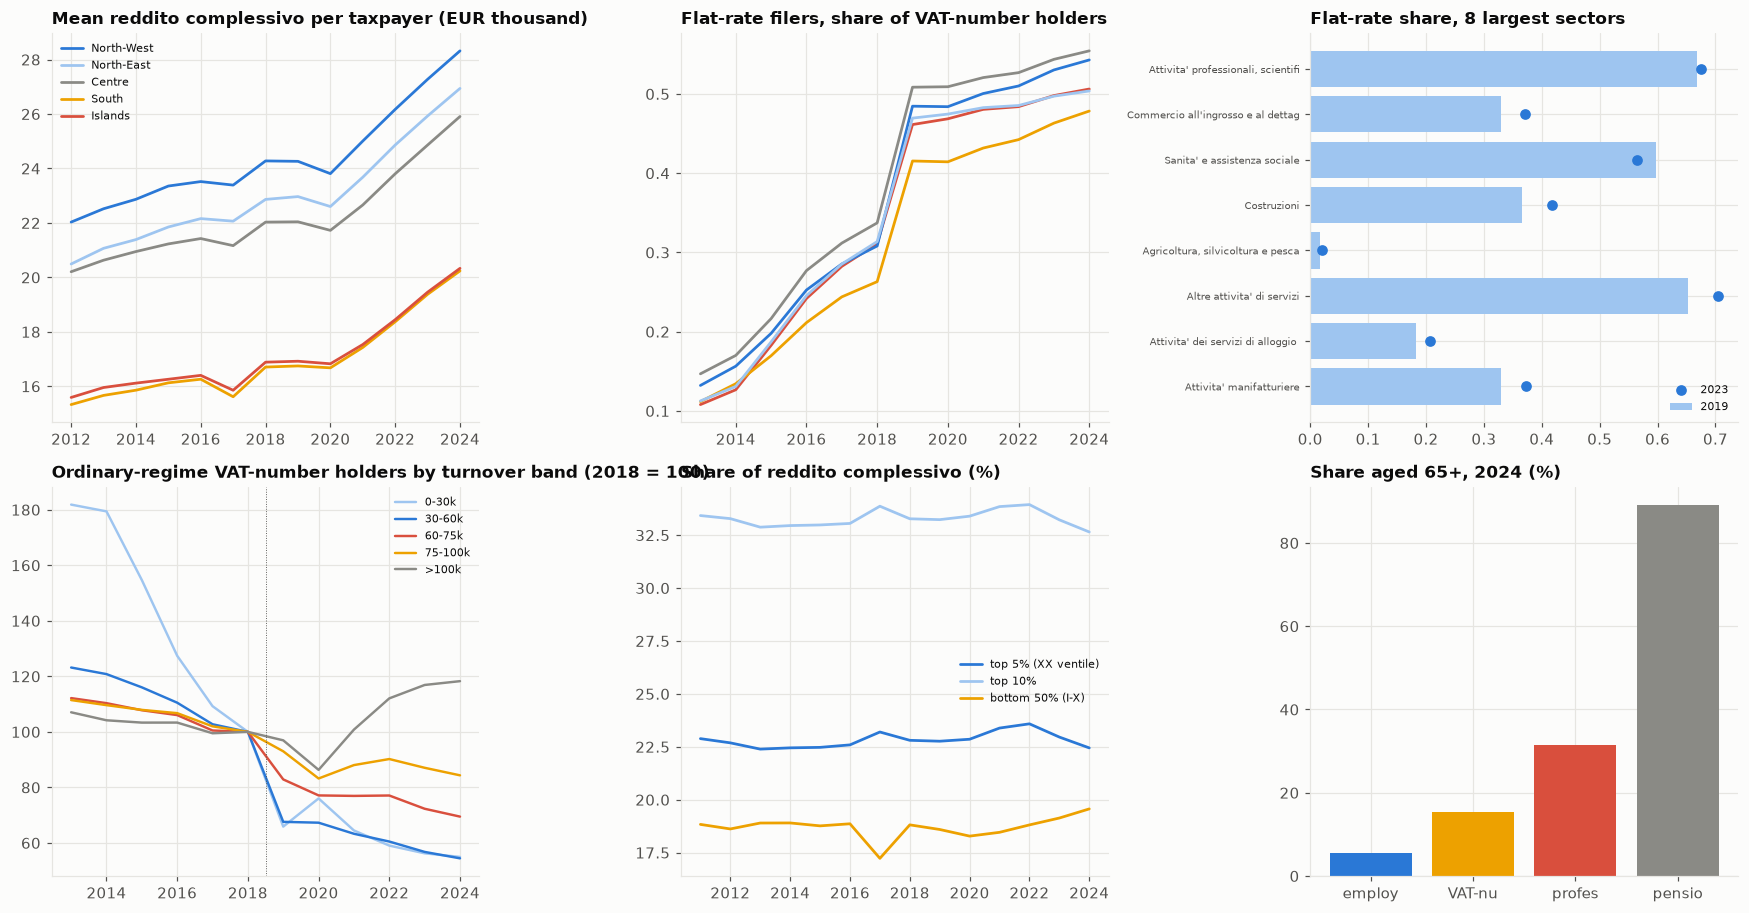

In [8]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8.4))
ax = axes[0, 0]
for g, c in [("North-West", "#2a78d6"), ("North-East", "#9ec5f0"), ("Centre", "#8a8a85"), ("South", "#eda100"), ("Islands", "#d94f3d")]: ax.plot(am.columns, am.loc[g] / 1000, label=g, color=c, lw=1.8)
ax.set_title("Mean reddito complessivo per taxpayer (EUR thousand)"); ax.legend(fontsize=7)
ax = axes[0, 1]; fa.T.plot(ax=ax, color=["#8a8a85", "#d94f3d", "#eda100", "#2a78d6", "#9ec5f0"], lw=1.8, legend=False); ax.set_title("Flat-rate filers, share of VAT-number holders"); ax.set_xlabel("")
ax = axes[0, 2]; sel = tab.head(8); y = np.arange(len(sel))[::-1]
ax.barh(y, sel["2019"], color="#9ec5f0", label="2019"); ax.scatter(sel["2023"], y, color="#2a78d6", zorder=3, label="2023"); ax.set_yticks(y, [i[:34] for i in sel.index], fontsize=6.5); ax.set_title("Flat-rate share, 8 largest sectors"); ax.legend(fontsize=7)
ax = axes[1, 0]; idx = (ordb.drop(index="<=0").div(ordb.drop(index="<=0")[2018], axis=0) * 100).T
for c, col in zip(idx.columns, ["#9ec5f0", "#2a78d6", "#d94f3d", "#eda100", "#8a8a85"], strict=False): ax.plot(idx.index, idx[c], label=c, color=col, lw=1.6)
ax.axvline(2018.5, color=INK2, lw=0.6, ls=":"); ax.set_title("Ordinary-regime VAT-number holders by turnover band (2018 = 100)"); ax.legend(fontsize=7)
ax = axes[1, 1]
for c, col in [("top 5% (XX ventile)", "#2a78d6"), ("top 10%", "#9ec5f0"), ("bottom 50% (I-X)", "#eda100")]: ax.plot(top.index, top[c], label=c, color=col, lw=1.8)
ax.set_title("Share of reddito complessivo (%)"); ax.legend(fontsize=7)
ax = axes[1, 2]
for g, c in [("employees", "#2a78d6"), ("VAT-number holders", "#eda100"), ("professionals", "#d94f3d"), ("pensioners", "#8a8a85")]: ax.bar(g[:6], ages[g].loc["oltre 64", 2024], color=c)
ax.set_title("Share aged 65+, 2024 (%)")
fig.tight_layout(); save(fig, "33_irpef_dims")

## Takeaways (MEF IRPEF return statistics, tax years 2008-2024; descriptive)
- **Data checks.** 842 files parse (the first batch of 238 plus 604 downloaded by the new crawler, 2 regional files empty on the server). One bug was found by the checks, not by eye: NACE section names with `;` split rows wrongly (retail trade, water supply and public administration were read as numbers like 7 or 5, so sector rows added up to only 84% of the total); and the section list changes in tax year 2024 (ATECO 2025). After the fix, class rows add up to the TOTALE row in all but one of 14,308 unsuppressed cells (0.7% off, on a tiny cell), the reported mean equals amount / taxpayers in 99.9% of 164,670 cells, and TOTALE taxpayers are identical across the income-class, region, sector, age and turnover tables for every group and year. 3.7% of cells are suppressed.
- **Regions: the North-South gap in declared income is stable.** Mean reddito complessivo per taxpayer in 2024 is 28.3 thousand EUR in the North-West, 26.9 in the North-East, 25.9 in the Centre, 20.3 in the Islands and 20.2 in the South; the South stands at 0.70 of the North-West in 2012 and 0.72 in 2024 (Lombardy 29.4 thousand, Calabria 18.5). VAT-number holders earn about as much as employees on ordinary income in the South and Islands (ratio 1.01 in 2024, 0.97-0.98 in 2013) and 7-17% more in the North (1.07 North-West, 1.17 North-East).
- **The flat-rate regimes spread everywhere, a bit more in the Centre.** The share of VAT-number holders in the flat-rate group rose from 11-15% (2013) to 48-55% (2024): Centre 55%, North-West 54%, Islands 51%, South 50%, North-East 48%; by region from 38% (Trentino-Alto Adige) and 43% (Basilicata) to 60% (Lazio). The regional differences are small next to the national rise. (This group, 52% of VAT-number holders in 2024, is larger than the 48.5% with positive forfettario net income in notebook 32: it also holds filers with zero net income.)
- **Sectors: the regime is a services phenomenon and the largest sectors differ.** Five sections hold 71% of the 3.8 million VAT-number holders in 2023 (professional and technical activities 1.01 million, trade 0.67, health and social work 0.43, construction 0.34, agriculture 0.24). The flat-rate share rose between 2013 and 2023 from 23% to 67% in professional activities, 6% to 37% in trade, 22% to 57% in health, 9% to 42% in construction and 2% to 21% in accommodation and food; agriculture stays at 2% (a separate VAT regime). Tax year 2024 follows the ATECO 2025 list and is left out of the sector comparison.
- **Age: the ordinary-regime professionals have aged.** Professionals aged 25-44 fell from 36% to 15% of the group between 2013 and 2024 and those over 64 rose from 12% to 32% (the group itself shrank from 0.95 to 0.53 million); entrepreneurs aged 25-44 fell from 38% to 23%. Among all VAT-number holders the 65+ share is 15.5% (11.8% in 2013) against 5.5% of employees (2.4%). The tables have no age split for the flat-rate filers, so that younger professionals moved into the flat regime is an inference.
- **Turnover: the ordinary regime lost small filers in 2019.** The number of VAT-number holders with a VAT declaration fell by 499 thousand between tax years 2018 and 2019: -254 thousand (-34%) with turnover up to 30,000 EUR, -177 thousand (-32%) between 30,000 and 60,000, -28 thousand (-17%) in the 60-75 thousand class that contains the EUR 65,000 threshold, and only -13 thousand (-7%) and -16 thousand (-3%) above, while the group without a VAT declaration (flat-rate and other exempt filers) grew by 543 thousand (forfettario filers +667 thousand in notebook 32) and now holds 56% of VAT-number holders. That is the pattern a higher threshold would produce, but it is a coincidence in time and cannot isolate the rule from the 2019 e-invoicing and other changes.
- **Top shares of declared income are stable.** The top 5% of taxpayers held 22.9% of reddito complessivo in 2011, 22.8% in 2019 and 22.5% in 2024 (peak 23.6% in 2022); the top 10% 33.4%, 33.2% and 32.7%; the top 25% 55.8% and 54.5% (2011 and 2024); the bottom half 18.8% and 19.6% (17.2% in 2017, distorted by the lowest-class anomaly of notebook 32). The median taxpayer's income (upper end of the tenth twentile) rose from 15.7 to 21.2 thousand EUR between 2012 and 2024 and the 90th percentile from 35.8 to 44.5. The top twentile's income in 2024 is 45% employment, 18% pensions, 12.5% self-employment, 6.5% business income, 3% buildings and 14% other (partnerships, miscellaneous); the first twentile holds zero and (before 2018) negative incomes and is mostly property income (49% in 2024).
- **Limits.** Declared ordinary income of those who file: it excludes flat-rate and flat-tax income (the 'cedolare secca' on rents, financial income taxed at source), non-filers and household structure, so top shares are understated and cannot be compared with the EU-SILC quintile shares of notebook 30 (equivalised disposable household income). The first twentile and the negative classes are unreliable before 2018. Regional means mix people who work in one region with filing residence. The sector, turnover and age tables have no flat-rate split except the sector and region tables (group `MIN`).
